Part A - Image Feature Extraction and Classification

In [2]:
import os
import time
import glob
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)

DATA_DIR   = "data"
OUTPUT_DIR = "outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

IMG_SIZE = 128          # all images resized to 128 x 128
RANDOM_STATE = 42

print("Setup done. OpenCV version:", cv2.__version__)

Setup done. OpenCV version: 5.0.0


In [3]:
for root, dirs, files in os.walk(DATA_DIR):
    depth = root.replace(DATA_DIR, "").count(os.sep)
    print("   " * depth + os.path.basename(root) + "/",
          f"[{len(files)} files]" if files else "")
    if depth >= 2:          # don't print every image name
        dirs[:] = []

data/ [1 files]
   asphalt/ 
      Cracks/ [200 files]
      NonCracks/ [200 files]


In [4]:
IMAGE_DIR = os.path.join(DATA_DIR, "asphalt")

LABEL_MAP = {
    "Cracks":    1,   # positive class = crack present
    "NonCracks": 0
}

VALID_EXT = ('.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff')

records = []
for folder, label in LABEL_MAP.items():
    folder_path = os.path.join(IMAGE_DIR, folder)
    for fname in sorted(os.listdir(folder_path)):
        if fname.lower().endswith(VALID_EXT):
            records.append({
                "filepath": os.path.join(folder_path, fname),
                "filename": fname,
                "folder":   folder,
                "label":    label
            })

files_df = pd.DataFrame(records)

print("Total images:", len(files_df))
print(files_df["folder"].value_counts(), "\n")
files_df.head()

Total images: 400
folder
Cracks       200
NonCracks    200
Name: count, dtype: int64 



,filepath,filename,folder,label
0,data\asphalt\Cracks\IMG_20180513_164959951_HDR...,IMG_20180513_164959951_HDR resized_448.jpg,Cracks,1
1,data\asphalt\Cracks\IMG_20180513_165129852_HDR...,IMG_20180513_165129852_HDR resized_448.jpg,Cracks,1
2,data\asphalt\Cracks\IMG_20180513_165150613_HDR...,IMG_20180513_165150613_HDR resized_448.jpg,Cracks,1
3,data\asphalt\Cracks\IMG_20180513_165345878_HDR...,IMG_20180513_165345878_HDR resized_448.jpg,Cracks,1
4,data\asphalt\Cracks\IMG_20180513_165349788_HDR...,IMG_20180513_165349788_HDR resized_448.jpg,Cracks,1


In [5]:
inspect = []
for fp in files_df["filepath"]:
    img = cv2.imread(fp, cv2.IMREAD_UNCHANGED)
    if img is None:
        inspect.append({"height": None, "width": None, "channels": None})
        continue
    h, w = img.shape[:2]
    ch = 1 if img.ndim == 2 else img.shape[2]
    inspect.append({"height": h, "width": w, "channels": ch})

inspect_df = pd.concat([files_df, pd.DataFrame(inspect)], axis=1)

print("Unreadable files:", inspect_df["height"].isna().sum())
print("\nUnique (height, width) combinations:")
print(inspect_df.groupby(["height", "width"]).size())
print("\nChannel counts:")
print(inspect_df["channels"].value_counts())
print("\nSize stats:")
print(inspect_df[["height", "width"]].describe().loc[["min", "max", "mean"]])

Unreadable files: 0

Unique (height, width) combinations:
height  width
448     448      400
dtype: int64

Channel counts:
channels
3    400
Name: count, dtype: int64

Size stats:
      height  width
min    448.0  448.0
max    448.0  448.0
mean   448.0  448.0


In [6]:
DARK_THRESH   = 60     # pixel below this = "dark"
BRIGHT_THRESH = 180    # pixel above this = "bright"
CANNY_LOW     = 100
CANNY_HIGH    = 200

def extract_features(filepath, img_size=IMG_SIZE):
    """Read one image -> return a dict of numeric features."""
    img = cv2.imread(filepath, cv2.IMREAD_COLOR)
    if img is None:
        return None

    # 1. resize to common size (compute reduction)
    img = cv2.resize(img, (img_size, img_size), interpolation=cv2.INTER_AREA)

    # 2. grayscale: cracks are an intensity pattern, colour is irrelevant
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    total_px = gray.size

    # ---- intensity statistics (NumPy) ----
    feats = {
        "mean_brightness": float(np.mean(gray)),
        "contrast_std":    float(np.std(gray)),
        "min_intensity":   float(np.min(gray)),
        "max_intensity":   float(np.max(gray)),
        "median_intensity":float(np.median(gray)),
        "intensity_range": float(np.max(gray) - np.min(gray)),
        "p10":             float(np.percentile(gray, 10)),
        "p90":             float(np.percentile(gray, 90)),
        "dark_ratio":      float(np.sum(gray < DARK_THRESH)   / total_px),
        "bright_ratio":    float(np.sum(gray > BRIGHT_THRESH) / total_px),
    }

    # ---- edge features (OpenCV Canny) ----
    edges = cv2.Canny(gray, CANNY_LOW, CANNY_HIGH)
    edge_count = int(np.sum(edges > 0))
    feats["edge_count"]   = edge_count
    feats["edge_density"] = edge_count / total_px

    return feats

In [7]:
t0 = time.time()

rows, failed = [], []
for _, r in files_df.iterrows():
    f = extract_features(r["filepath"])
    if f is None:
        failed.append(r["filename"])
        continue
    f["filename"] = r["filename"]
    f["folder"]   = r["folder"]
    f["label"]    = r["label"]
    rows.append(f)

feature_df = pd.DataFrame(rows)
extract_time = time.time() - t0

print(f"Extracted {len(feature_df)} rows in {extract_time:.2f}s  "
      f"({extract_time/len(feature_df)*1000:.1f} ms/image)")
print("Failed:", failed)

feature_df.to_csv(os.path.join(OUTPUT_DIR, "image_features.csv"), index=False)
feature_df.head()

Extracted 400 rows in 2.71s  (6.8 ms/image)
Failed: []


,mean_brightness,contrast_std,min_intensity,max_intensity,median_intensity,intensity_range,p10,p90,dark_ratio,bright_ratio,edge_count,edge_density,filename,folder,label
0,122.098999,25.436979,43.0,240.0,120.0,197.0,91.0,157.0,0.002625,0.018372,4207,0.256775,IMG_20180513_164959951_HDR resized_448.jpg,Cracks,1
1,131.829102,20.024508,31.0,223.0,133.0,192.0,107.0,154.0,0.003662,0.008850,2966,0.181030,IMG_20180513_165129852_HDR resized_448.jpg,Cracks,1
2,121.169312,24.449943,11.0,224.0,120.0,213.0,94.0,152.0,0.013794,0.018494,3171,0.193542,IMG_20180513_165150613_HDR resized_448.jpg,Cracks,1
3,130.120544,19.907579,36.0,250.0,131.0,214.0,105.0,154.0,0.000732,0.005920,3952,0.241211,IMG_20180513_165345878_HDR resized_448.jpg,Cracks,1
4,131.078552,20.115614,41.0,249.0,132.0,208.0,106.0,154.0,0.002014,0.009460,3584,0.218750,IMG_20180513_165349788_HDR resized_448.jpg,Cracks,1


In [8]:
feature_cols = [c for c in feature_df.columns
                if c not in ("filename", "folder", "label")]

comparison = feature_df.groupby("folder")[feature_cols].mean().T
comparison["difference"] = comparison["Cracks"] - comparison["NonCracks"]
comparison.round(4)

folder,Cracks,NonCracks,difference
mean_brightness,144.2490,157.5145,-13.2655
contrast_std,24.6087,17.5285,7.0802
min_intensity,41.6750,89.7500,-48.0750
max_intensity,242.7800,235.0850,7.6950
median_intensity,144.8075,157.2500,-12.4425
intensity_range,201.1050,145.3350,55.7700
p10,113.5695,135.5515,-21.9820
p90,174.4700,179.5600,-5.0900
dark_ratio,0.0071,0.0001,0.0070
bright_ratio,0.1499,0.1179,0.0321


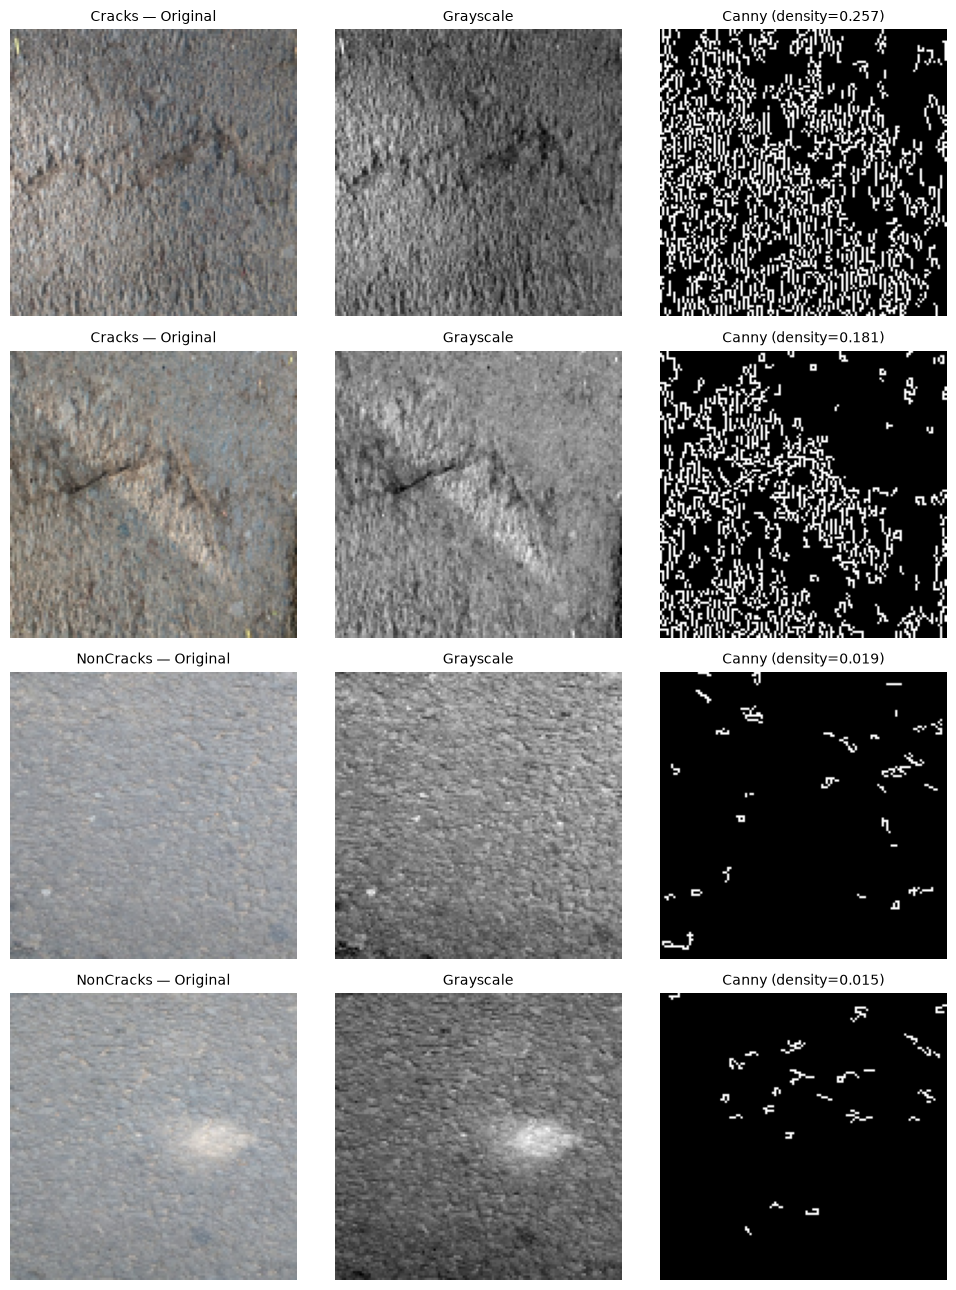

In [9]:
def viz_pipeline(filepath, img_size=IMG_SIZE):
    img  = cv2.imread(filepath, cv2.IMREAD_COLOR)
    img  = cv2.resize(img, (img_size, img_size), interpolation=cv2.INTER_AREA)
    rgb  = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    edges= cv2.Canny(gray, CANNY_LOW, CANNY_HIGH)
    return rgb, gray, edges

samples = [
    files_df[files_df.folder == "Cracks"].iloc[0],
    files_df[files_df.folder == "Cracks"].iloc[1],
    files_df[files_df.folder == "NonCracks"].iloc[0],
    files_df[files_df.folder == "NonCracks"].iloc[1],
]

fig, axes = plt.subplots(len(samples), 3, figsize=(10, 13))
for i, s in enumerate(samples):
    rgb, gray, edges = viz_pipeline(s["filepath"])
    ed = np.sum(edges > 0) / edges.size
    for j, (im, cmap, t) in enumerate([
        (rgb,  None,   f"{s['folder']} — Original"),
        (gray, "gray", "Grayscale"),
        (edges,"gray", f"Canny (density={ed:.3f})")
    ]):
        axes[i, j].imshow(im, cmap=cmap)
        axes[i, j].set_title(t, fontsize=10)
        axes[i, j].axis("off")

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "canny_samples.png"), dpi=130, bbox_inches="tight")
plt.show()

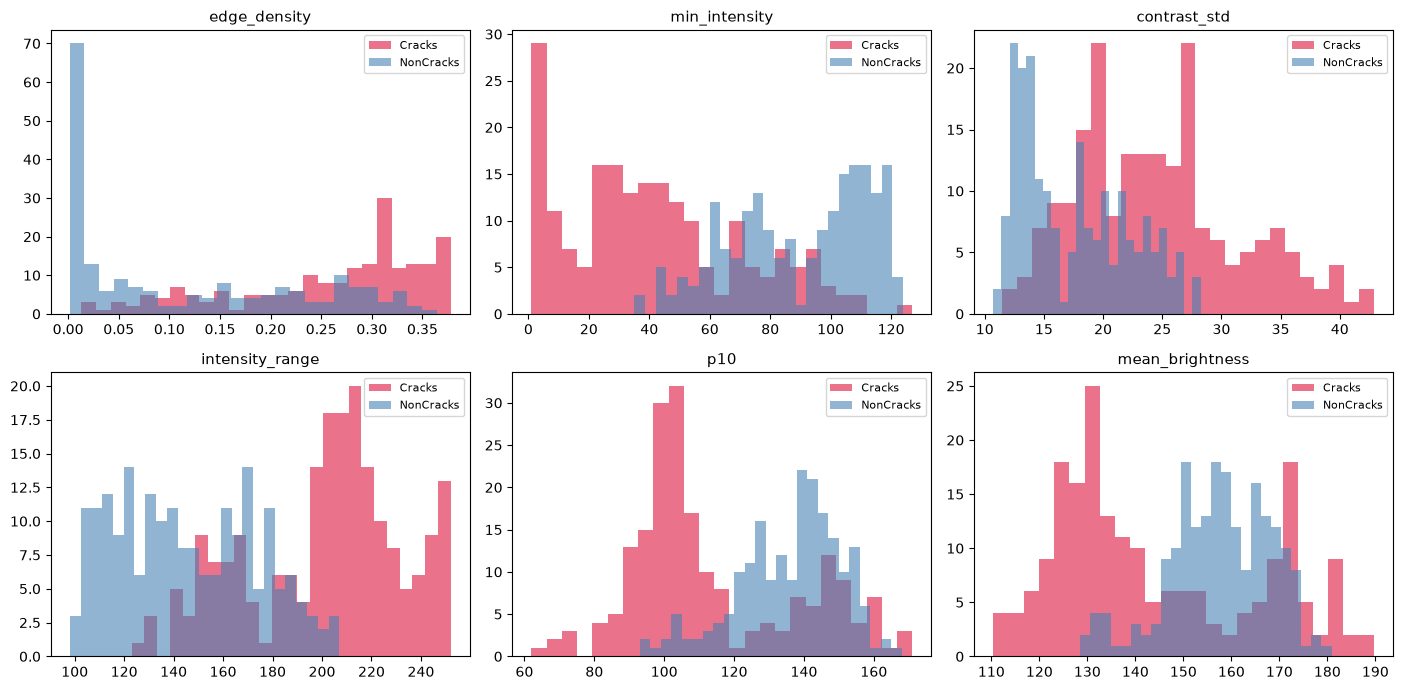

In [10]:
key_feats = ["edge_density", "min_intensity", "contrast_std",
             "intensity_range", "p10", "mean_brightness"]

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, f in zip(axes.ravel(), key_feats):
    for folder, color in [("Cracks", "crimson"), ("NonCracks", "steelblue")]:
        ax.hist(feature_df[feature_df.folder == folder][f],
                bins=25, alpha=0.6, label=folder, color=color)
    ax.set_title(f, fontsize=11)
    ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "feature_distributions.png"), dpi=130, bbox_inches="tight")
plt.show()

In [11]:
X = feature_df[feature_cols].values
y = feature_df["label"].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)   # fit on TRAIN only
X_test_s  = scaler.transform(X_test)        # test just gets transformed

print("Train:", X_train.shape, " Test:", X_test.shape)
print("Train class balance:", np.bincount(y_train))
print("Test  class balance:", np.bincount(y_test))

Train: (320, 12)  Test: (80, 12)
Train class balance: [160 160]
Test  class balance: [40 40]


In [12]:
models = {
    "Logistic Regression": (LogisticRegression(max_iter=1000, random_state=RANDOM_STATE), True),
    "SVM (RBF)":           (SVC(kernel="rbf", random_state=RANDOM_STATE),                True),
    "Random Forest":       (RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE), False),
    "KNN (k=5)":           (KNeighborsClassifier(n_neighbors=5),                          True),
}

results, preds = [], {}

for name, (model, needs_scaling) in models.items():
    Xtr = X_train_s if needs_scaling else X_train
    Xte = X_test_s  if needs_scaling else X_test

    t0 = time.perf_counter()
    model.fit(Xtr, y_train)
    train_time = time.perf_counter() - t0

    t0 = time.perf_counter()
    y_pred = model.predict(Xte)
    predict_time = time.perf_counter() - t0

    preds[name] = y_pred
    results.append({
        "Model":        name,
        "Accuracy":     accuracy_score(y_test, y_pred),
        "Precision":    precision_score(y_test, y_pred),
        "Recall":       recall_score(y_test, y_pred),
        "F1":           f1_score(y_test, y_pred),
        "Train time (s)":   train_time,
        "Predict time (s)": predict_time,
    })

results_df = pd.DataFrame(results).sort_values("F1", ascending=False).reset_index(drop=True)
results_df.to_csv(os.path.join(OUTPUT_DIR, "image_model_results.csv"), index=False)
results_df.round(4)

,Model,Accuracy,Precision,Recall,F1,Train time (s),Predict time (s)
0,Random Forest,0.9250,0.9048,0.950,0.9268,0.4850,0.0371
1,Logistic Regression,0.9250,0.9250,0.925,0.9250,0.0600,0.0008
2,KNN (k=5),0.9250,0.9250,0.925,0.9250,0.0471,0.0045
3,SVM (RBF),0.9125,0.9024,0.925,0.9136,0.0055,0.0013


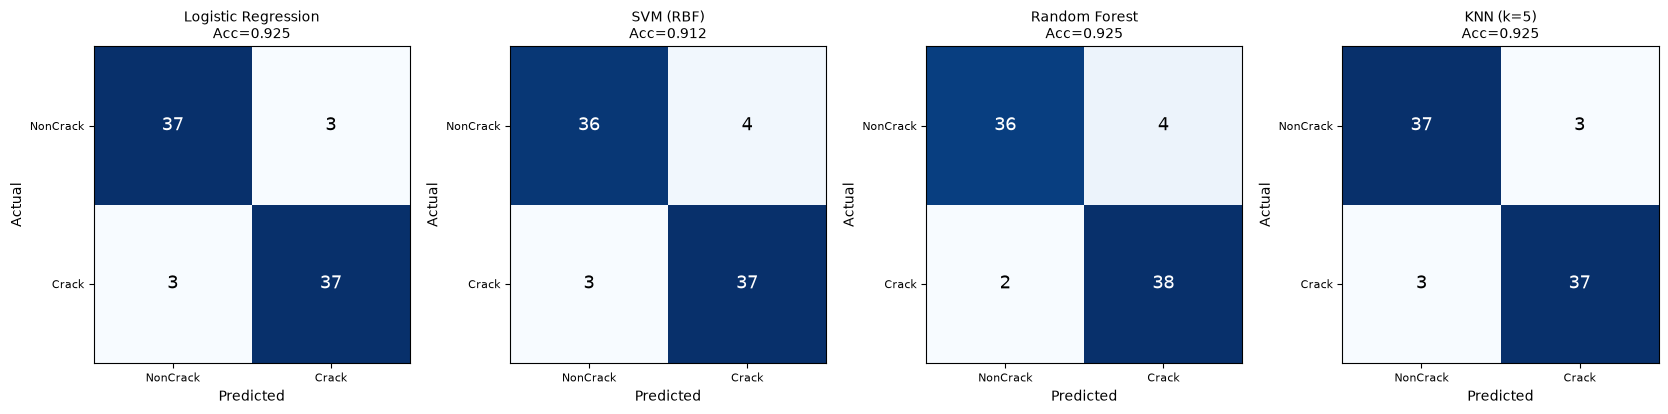


Best model: Random Forest

              precision    recall  f1-score   support

    NonCrack       0.95      0.90      0.92        40
       Crack       0.90      0.95      0.93        40

    accuracy                           0.93        80
   macro avg       0.93      0.93      0.92        80
weighted avg       0.93      0.93      0.92        80



In [13]:
fig, axes = plt.subplots(1, len(preds), figsize=(4.2 * len(preds), 4))

for ax, (name, y_pred) in zip(axes, preds.items()):
    cm = confusion_matrix(y_test, y_pred)
    ax.imshow(cm, cmap="Blues")
    ax.set_title(f"{name}\nAcc={accuracy_score(y_test, y_pred):.3f}", fontsize=10)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["NonCrack", "Crack"], fontsize=8)
    ax.set_yticks([0, 1]); ax.set_yticklabels(["NonCrack", "Crack"], fontsize=8)
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha="center", va="center",
                    color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=13)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "confusion_matrices.png"), dpi=130, bbox_inches="tight")
plt.show()

best = results_df.iloc[0]["Model"]
print(f"\nBest model: {best}\n")
print(classification_report(y_test, preds[best], target_names=["NonCrack", "Crack"]))

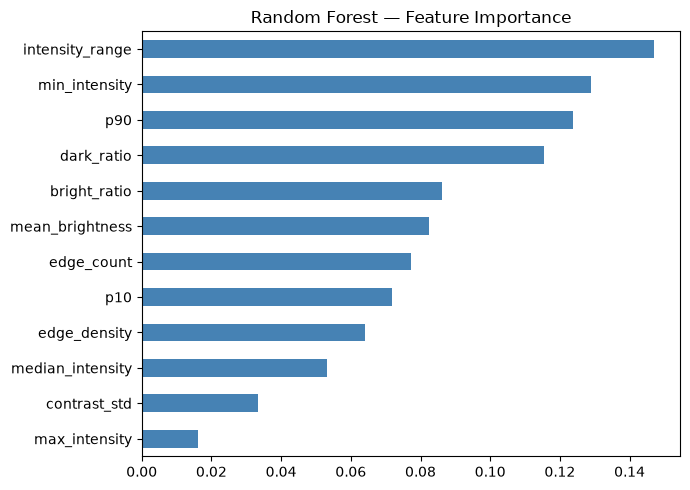

intensity_range     0.1471
min_intensity       0.1290
p90                 0.1237
dark_ratio          0.1154
bright_ratio        0.0863
mean_brightness     0.0824
edge_count          0.0774
p10                 0.0717
edge_density        0.0640
median_intensity    0.0533
contrast_std        0.0335
max_intensity       0.0161
dtype: float64

In [14]:
rf = models["Random Forest"][0]
imp = pd.Series(rf.feature_importances_, index=feature_cols).sort_values()

plt.figure(figsize=(7, 5))
imp.plot(kind="barh", color="steelblue")
plt.title("Random Forest — Feature Importance")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "feature_importance.png"), dpi=130, bbox_inches="tight")
plt.show()

imp.sort_values(ascending=False).round(4)

Part B - Text Vectorization and Spam Classification

In [3]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
import re

email_path = os.path.join(DATA_DIR, "emails.csv")   # adjust filename if different
emails = pd.read_csv(email_path)

print("Shape:", emails.shape)
print("\nFirst 10 columns:", list(emails.columns[:10]))
print("Last 5 columns:", list(emails.columns[-5:]))
print("\nDtypes:", emails.dtypes.value_counts().to_dict())
emails.head(3)

Shape: (5172, 3002)

First 10 columns: ['Email No.', 'the', 'to', 'ect', 'and', 'for', 'of', 'a', 'you', 'hou']
Last 5 columns: ['military', 'allowing', 'ff', 'dry', 'Prediction']

Dtypes: {dtype('int64'): 3001, <StringDtype(storage='python', na_value=nan)>: 1}


,Email No.,the,to,ect,and,for,of,a,you,hou,...,connevey,jay,valued,lay,infrastructure,military,allowing,ff,dry,Prediction
0,Email 1,0,0,1,0,0,0,2,0,0,...,0,0,0,0,0,0,0,0,0,0
1,Email 2,8,13,24,6,6,2,102,1,27,...,0,0,0,0,0,0,0,1,0,0
2,Email 3,0,0,1,0,0,0,8,0,0,...,0,0,0,0,0,0,0,0,0,0


Emails: 5172 | Vocabulary columns: 3000
Prediction
0    3672
1    1500
Name: count, dtype: int64
Prediction
0    0.71
1    0.29
Name: proportion, dtype: float64


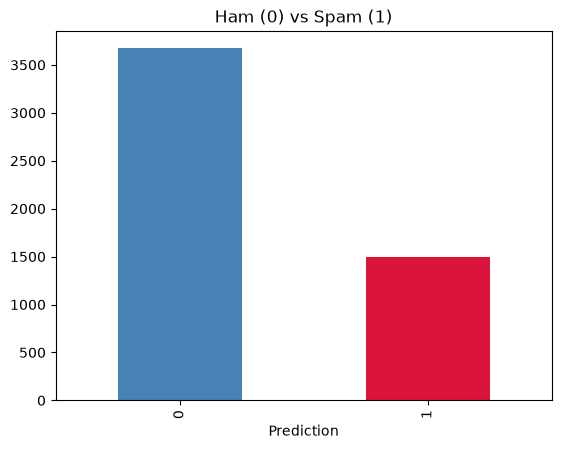


Nulls: 0
Duplicate rows (excl. ID): 541


In [4]:
LABEL_COL = "Prediction"
word_cols = [c for c in emails.columns if c not in ("Email No.", LABEL_COL)]

print("Emails:", len(emails), "| Vocabulary columns:", len(word_cols))
print(emails[LABEL_COL].value_counts())
print(emails[LABEL_COL].value_counts(normalize=True).round(3))

emails[LABEL_COL].value_counts().plot(kind="bar", color=["steelblue", "crimson"])
plt.title("Ham (0) vs Spam (1)"); plt.show()

print("\nNulls:", emails.isna().sum().sum())
print("Duplicate rows (excl. ID):", emails.drop(columns="Email No.").duplicated().sum())

In [5]:
words = np.array(word_cols)
counts = emails[word_cols].values

texts = [" ".join(np.repeat(words, row)) for row in counts]
emails["text"] = texts

print(emails["text"].str.split().str.len().describe().round(1))
emails[["text", LABEL_COL]].head(3)

count     5172.0
mean      1165.3
std       1760.1
min          8.0
25%        257.8
50%        577.0
75%       1333.5
max      29178.0
Name: text, dtype: float64


,text,Prediction
0,ect a a is i i s s s as re re e e e e t t t t ...,0
1,the the the the the the the the to to to to to...,0
2,ect a a a a a a a a in in in in on on i i i i ...,0


In [6]:
def clean_text(s):
    s = s.lower()
    s = re.sub(r"[^a-z\s]", " ", s)      # keep letters only
    s = re.sub(r"\s+", " ", s).strip()   # collapse whitespace
    return s

emails["clean_text"] = emails["text"].apply(clean_text)

# --- sanity checks ---
n_empty = (emails["clean_text"].str.len() == 0).sum()
print("Empty emails (no vocab words):", n_empty)

DROP_DUPLICATES = True
if DROP_DUPLICATES:
    before = len(emails)
    emails = emails.drop_duplicates(subset="clean_text").reset_index(drop=True)
    print(f"Dropped {before - len(emails)} duplicate texts -> {len(emails)} left")

# --- split BEFORE vectorising ---
Xt_train, Xt_test, yt_train, yt_test = train_test_split(
    emails["clean_text"], emails[LABEL_COL],
    test_size=0.2, random_state=RANDOM_STATE, stratify=emails[LABEL_COL]
)

print("Train:", len(Xt_train), "| Test:", len(Xt_test))
print("Train spam ratio:", round(yt_train.mean(), 3),
      "| Test spam ratio:", round(yt_test.mean(), 3))

C:\Users\Administrator\AppData\Local\Temp\ipykernel_15136\3209164171.py:7: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  emails["clean_text"] = emails["text"].apply(clean_text)


Empty emails (no vocab words): 0
Dropped 541 duplicate texts -> 4631 left
Train: 3704 | Test: 927
Train spam ratio: 0.316 | Test spam ratio: 0.315


In [8]:
def run_text_experiment(vec, vec_name, tag="Original"):
    """Vectorise (fit on train only), train 3 models, time everything."""
    t0 = time.perf_counter()
    Xtr = vec.fit_transform(Xt_train)
    vec_time = time.perf_counter() - t0
    Xte = vec.transform(Xt_test)

    clfs = {
        "Naive Bayes":         MultinomialNB(),
        "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
        "LinearSVC":           LinearSVC(random_state=RANDOM_STATE),
    }

    rows, cms = [], {}
    for cname, clf in clfs.items():
        t0 = time.perf_counter()
        clf.fit(Xtr, yt_train)
        train_time = time.perf_counter() - t0

        t0 = time.perf_counter()
        yp = clf.predict(Xte)
        pred_time = time.perf_counter() - t0

        cms[(vec_name, cname)] = confusion_matrix(yt_test, yp)
        rows.append({
            "Approach":         tag,
            "Representation":   vec_name,
            "Model":            cname,
            "# Features":       Xtr.shape[1],
            "Vectorise (s)":    vec_time,
            "Train (s)":        train_time,
            "Predict (s)":      pred_time,
            "Accuracy":         accuracy_score(yt_test, yp),
            "Precision":        precision_score(yt_test, yp),
            "Recall":           recall_score(yt_test, yp),
            "F1":               f1_score(yt_test, yp),
        })
    return rows, cms

all_rows, all_cms = [], {}
for vec_name, vec in [("CountVectorizer", CountVectorizer()),
                      ("TF-IDF",          TfidfVectorizer())]:
    r, c = run_text_experiment(vec, vec_name)
    all_rows += r
    all_cms.update(c)

text_results = pd.DataFrame(all_rows)
text_results.to_csv(os.path.join(OUTPUT_DIR, "text_results_original.csv"), index=False)
text_results.round(4)

c:\Users\Administrator\Desktop\ML Lab 6\.venv\Lib\site-packages\sklearn\svm\_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


,Approach,Representation,Model,# Features,Vectorise (s),Train (s),Predict (s),Accuracy,Precision,Recall,F1
0,Original,CountVectorizer,Naive Bayes,2974,2.2404,0.0075,0.0026,0.9450,0.8825,0.9521,0.9160
1,Original,CountVectorizer,Logistic Regression,2974,2.2404,0.5635,0.0013,0.9676,0.9338,0.9658,0.9495
2,Original,CountVectorizer,LinearSVC,2974,2.2404,2.1435,0.0015,0.9687,0.9398,0.9623,0.9509
3,Original,TF-IDF,Naive Bayes,2974,2.0064,0.0076,0.0016,0.9450,0.8875,0.9452,0.9154
4,Original,TF-IDF,Logistic Regression,2974,2.0064,0.0683,0.0011,0.9720,0.9618,0.9486,0.9552
5,Original,TF-IDF,LinearSVC,2974,2.0064,0.0717,0.0016,0.9827,0.9759,0.9692,0.9725


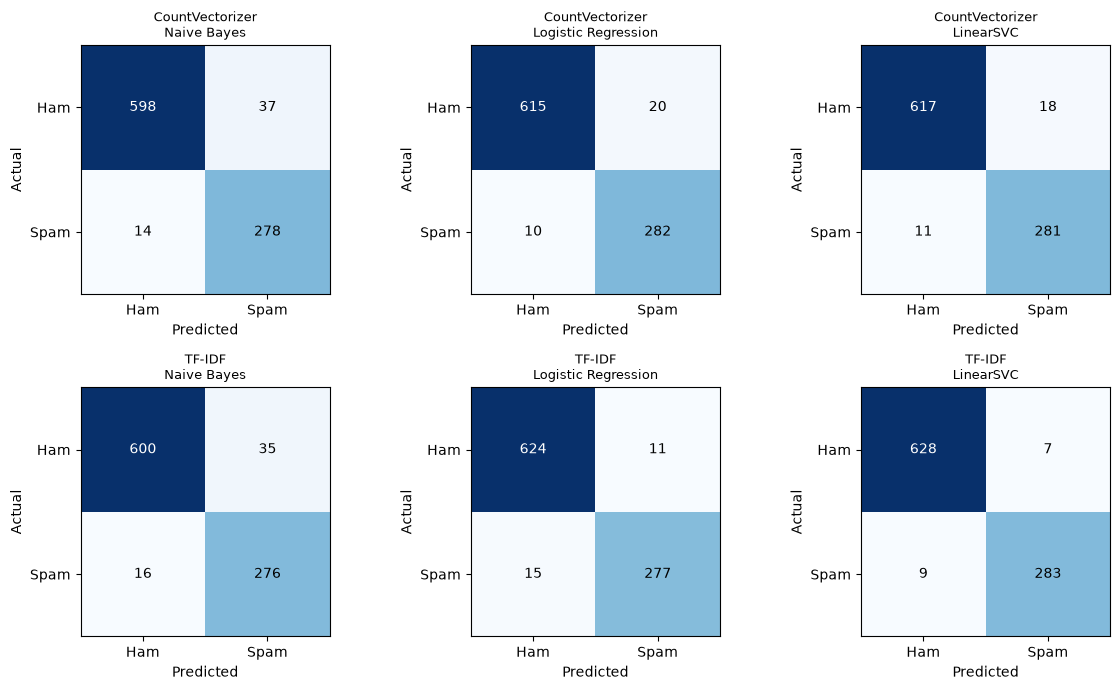

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for ax, ((vn, cn), cm) in zip(axes.ravel(), all_cms.items()):
    ax.imshow(cm, cmap="Blues")
    ax.set_title(f"{vn}\n{cn}", fontsize=9)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["Ham", "Spam"])
    ax.set_yticks([0, 1]); ax.set_yticklabels(["Ham", "Spam"])
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha="center", va="center",
                    color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "text_confusion_matrices.png"), dpi=130, bbox_inches="tight")
plt.show()

In [10]:
summary = (text_results
           .groupby("Representation")[["# Features", "Vectorise (s)", "Train (s)",
                                       "Predict (s)", "Accuracy", "F1"]]
           .mean())
summary.round(4)

,# Features,Vectorise (s),Train (s),Predict (s),Accuracy,F1
Representation,,,,,,
CountVectorizer,2974.0,2.2404,0.9048,0.0018,0.9604,0.9388
TF-IDF,2974.0,2.0064,0.0492,0.0014,0.9666,0.9477


Part C - Improve the Representation

In [11]:
variants = {
    "Original (3000)":      dict(),
    "+ stop words":         dict(stop_words="english"),
    "+ min_df=10":          dict(min_df=10),
    "max_features=1000":    dict(max_features=1000),
    "max_features=500":     dict(max_features=500),
    "stop words + top 500": dict(stop_words="english", max_features=500),
}

rows = []
for tag, params in variants.items():
    r, _ = run_text_experiment(CountVectorizer(**params), "CountVectorizer", tag=tag)
    rows += r

variant_df = pd.DataFrame(rows)
variant_df.to_csv(os.path.join(OUTPUT_DIR, "text_results_variants.csv"), index=False)

summary_c = (variant_df.groupby("Approach", sort=False)
             [["# Features", "Vectorise (s)", "Train (s)", "Predict (s)",
               "Accuracy", "F1"]].mean())
summary_c.round(4)

c:\Users\Administrator\Desktop\ML Lab 6\.venv\Lib\site-packages\sklearn\svm\_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
c:\Users\Administrator\Desktop\ML Lab 6\.venv\Lib\site-packages\sklearn\svm\_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
c:\Users\Administrator\Desktop\ML Lab 6\.venv\Lib\site-packages\sklearn\svm\_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
c:\Users\Administrator\Desktop\ML Lab 6\.venv\Lib\site-packages\sklearn\svm\_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
c:\Users\Administrator\Desktop\ML Lab 6\.venv\Lib\site-packages\sklearn\svm\_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
c:\Users\Administrator\Desktop\ML L

,# Features,Vectorise (s),Train (s),Predict (s),Accuracy,F1
Approach,,,,,,
Original (3000),2974.0,2.0889,0.9423,0.0017,0.9604,0.9388
+ stop words,2738.0,1.9979,0.7064,0.0017,0.9561,0.9320
+ min_df=10,2888.0,2.0684,0.8539,0.0015,0.9604,0.9389
max_features=1000,1000.0,1.9987,0.7401,0.0017,0.9565,0.9328
max_features=500,500.0,1.9621,0.6885,0.0013,0.9479,0.9195
stop words + top 500,500.0,1.9406,0.5110,0.0011,0.9479,0.9192


In [12]:
IMPROVED = "stop words + top 500"   # change after seeing C1

cmp = variant_df[variant_df.Approach.isin(["Original (3000)", IMPROVED])]
cmp = cmp.pivot(index="Model", columns="Approach",
                values=["# Features", "Train (s)", "Accuracy", "F1"])
cmp.round(4)

# Features                            Train (s)  \
Approach            Original (3000) stop words + top 500 Original (3000)   
Model                                                                      
LinearSVC                    2974.0                500.0          2.2208   
Logistic Regression          2974.0                500.0          0.5977   
Naive Bayes                  2974.0                500.0          0.0083   

                                                Accuracy                       \
Approach            stop words + top 500 Original (3000) stop words + top 500   
Model                                                                           
LinearSVC                         1.1771          0.9687               0.9644   
Logistic Regression               0.3506          0.9676               0.9676   
Naive Bayes                       0.0053          0.9450               0.9115   

                                 F1                       
Approach            Original (3000) stop words + top 500  
Model                                                     
LinearSVC                    0.9509               0.9434  
Logistic Regression          0.9495               0.9492  
Naive Bayes                  0.9160               0.8651

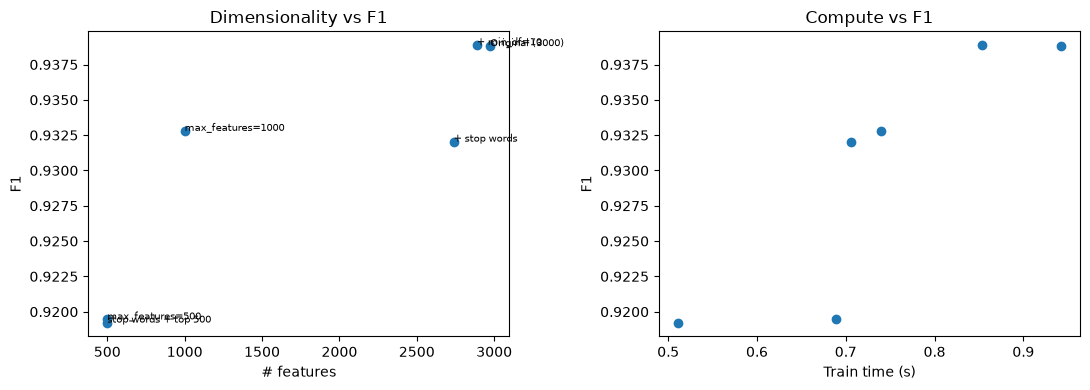

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
s = summary_c.reset_index()

ax[0].plot(s["# Features"], s["F1"], "o")
for _, r in s.iterrows():
    ax[0].annotate(r["Approach"], (r["# Features"], r["F1"]), fontsize=7)
ax[0].set_xlabel("# features"); ax[0].set_ylabel("F1"); ax[0].set_title("Dimensionality vs F1")

ax[1].scatter(s["Train (s)"], s["F1"])
ax[1].set_xlabel("Train time (s)"); ax[1].set_ylabel("F1"); ax[1].set_title("Compute vs F1")

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "text_tradeoff.png"), dpi=130, bbox_inches="tight")
plt.show()

In [15]:
feature_df = pd.read_csv(os.path.join(OUTPUT_DIR, "image_features.csv"))
feature_cols = [c for c in feature_df.columns
                if c not in ("filename", "folder", "label")]
print(feature_df.shape)

(400, 15)


In [16]:
def evaluate_image_features(fdf, tag):
    cols = [c for c in fdf.columns if c not in ("filename", "folder", "label")]
    X, y = fdf[cols].values, fdf["label"].values
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2,
                                          random_state=RANDOM_STATE, stratify=y)
    sc = StandardScaler().fit(Xtr)
    Xtr_s, Xte_s = sc.transform(Xtr), sc.transform(Xte)

    mods = {
        "Logistic Regression": (LogisticRegression(max_iter=1000, random_state=RANDOM_STATE), True),
        "SVM (RBF)":           (SVC(kernel="rbf", random_state=RANDOM_STATE), True),
        "Random Forest":       (RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE), False),
        "KNN (k=5)":           (KNeighborsClassifier(n_neighbors=5), True),
    }
    out = []
    for n, (m, scaled) in mods.items():
        a, b = (Xtr_s, Xte_s) if scaled else (Xtr, Xte)
        t0 = time.perf_counter(); m.fit(a, ytr); tt = time.perf_counter() - t0
        t0 = time.perf_counter(); p = m.predict(b); tp = time.perf_counter() - t0
        out.append({"Approach": tag, "Model": n, "# Features": len(cols),
                    "Train (s)": tt, "Predict (s)": tp,
                    "Accuracy": accuracy_score(yte, p),
                    "Precision": precision_score(yte, p),
                    "Recall": recall_score(yte, p),
                    "F1": f1_score(yte, p)})
    return pd.DataFrame(out)

res_orig = evaluate_image_features(feature_df.copy(), "Original (dark<60)")
res_orig.round(4)

,Approach,Model,# Features,Train (s),Predict (s),Accuracy,Precision,Recall,F1
0,Original (dark<60),Logistic Regression,12,0.0061,0.0003,0.9250,0.9250,0.925,0.9250
1,Original (dark<60),SVM (RBF),12,0.0025,0.0006,0.9125,0.9024,0.925,0.9136
2,Original (dark<60),Random Forest,12,0.1875,0.0108,0.9250,0.9048,0.950,0.9268
3,Original (dark<60),KNN (k=5),12,0.0028,0.0031,0.9250,0.9250,0.925,0.9250


In [19]:
IMAGE_DIR = os.path.join(DATA_DIR, "asphalt")
LABEL_MAP = {"Cracks": 1, "NonCracks": 0}
VALID_EXT = ('.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff')

records = []
for folder, label in LABEL_MAP.items():
    folder_path = os.path.join(IMAGE_DIR, folder)
    for fname in sorted(os.listdir(folder_path)):
        if fname.lower().endswith(VALID_EXT):
            records.append({"filepath": os.path.join(folder_path, fname),
                            "filename": fname, "folder": folder, "label": label})
files_df = pd.DataFrame(records)

DARK_THRESH, BRIGHT_THRESH = 60, 180
CANNY_LOW, CANNY_HIGH = 100, 200

def extract_features(filepath, img_size=IMG_SIZE):
    img = cv2.imread(filepath, cv2.IMREAD_COLOR)
    if img is None:
        return None
    img = cv2.resize(img, (img_size, img_size), interpolation=cv2.INTER_AREA)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    total_px = gray.size
    feats = {
        "mean_brightness":  float(np.mean(gray)),
        "contrast_std":     float(np.std(gray)),
        "min_intensity":    float(np.min(gray)),
        "max_intensity":    float(np.max(gray)),
        "median_intensity": float(np.median(gray)),
        "intensity_range":  float(np.max(gray) - np.min(gray)),
        "p10":              float(np.percentile(gray, 10)),
        "p90":              float(np.percentile(gray, 90)),
        "dark_ratio":       float(np.sum(gray < DARK_THRESH)   / total_px),
        "bright_ratio":     float(np.sum(gray > BRIGHT_THRESH) / total_px),
    }
    edges = cv2.Canny(gray, CANNY_LOW, CANNY_HIGH)
    edge_count = int(np.sum(edges > 0))
    feats["edge_count"] = edge_count
    feats["edge_density"] = edge_count / total_px
    return feats

print(len(files_df), "images ready")

400 images ready


In [20]:
DARK_THRESH = 100                       # was 60

rows = []
for _, r in files_df.iterrows():
    f = extract_features(r["filepath"])
    f.update(filename=r["filename"], folder=r["folder"], label=r["label"])
    rows.append(f)
feature_df_imp = pd.DataFrame(rows)
feature_df_imp.to_csv(os.path.join(OUTPUT_DIR, "image_features_improved.csv"), index=False)

print("dark_ratio mean by class (threshold 100):")
print(feature_df_imp.groupby("folder")["dark_ratio"].mean().round(4))

res_imp = evaluate_image_features(feature_df_imp, "Improved (dark<100)")
image_cmp = pd.concat([res_orig, res_imp]).reset_index(drop=True)
image_cmp.to_csv(os.path.join(OUTPUT_DIR, "image_original_vs_improved.csv"), index=False)

DARK_THRESH = 60                        # restore global
image_cmp.round(4)

dark_ratio mean by class (threshold 100):
folder
Cracks       0.0772
NonCracks    0.0093
Name: dark_ratio, dtype: float64


,Approach,Model,# Features,Train (s),Predict (s),Accuracy,Precision,Recall,F1
0,Original (dark<60),Logistic Regression,12,0.0061,0.0003,0.9250,0.9250,0.925,0.9250
1,Original (dark<60),SVM (RBF),12,0.0025,0.0006,0.9125,0.9024,0.925,0.9136
2,Original (dark<60),Random Forest,12,0.1875,0.0108,0.9250,0.9048,0.950,0.9268
3,Original (dark<60),KNN (k=5),12,0.0028,0.0031,0.9250,0.9250,0.925,0.9250
4,Improved (dark<100),Logistic Regression,12,0.0046,0.0002,0.9250,0.9250,0.925,0.9250
5,Improved (dark<100),SVM (RBF),12,0.0015,0.0005,0.9125,0.9024,0.925,0.9136
6,Improved (dark<100),Random Forest,12,0.1887,0.0111,0.9375,0.9268,0.950,0.9383
7,Improved (dark<100),KNN (k=5),12,0.0009,0.0014,0.9250,0.9250,0.925,0.9250


In [21]:
#SUMMARY :
# ---- IMAGE ----
bo = res_orig.sort_values("F1", ascending=False).iloc[0]
bi = res_imp.sort_values("F1", ascending=False).iloc[0]
print("IMAGE (Part A -> Part C)")
print(f"  Change: DARK_THRESH 60 -> 100 (features: {int(bo['# Features'])} -> {int(bi['# Features'])})")
print(f"  Best original : {bo['Model']:<20} Acc={bo['Accuracy']:.3f}  Recall={bo['Recall']:.3f}  F1={bo['F1']:.3f}")
print(f"  Best improved : {bi['Model']:<20} Acc={bi['Accuracy']:.3f}  Recall={bi['Recall']:.3f}  F1={bi['F1']:.3f}")
print(f"  F1 change     : {bi['F1'] - bo['F1']:+.3f}")
print(f"  Mean F1 across models: {res_orig['F1'].mean():.3f} -> {res_imp['F1'].mean():.3f}")

# ---- TEXT ----
to = variant_df[variant_df.Approach == "Original (3000)"]
ti = variant_df[variant_df.Approach == IMPROVED]
print("\nTEXT (CountVectorizer)")
print(f"  Change: {IMPROVED}")
print(f"  Features   : {int(to['# Features'].iloc[0])} -> {int(ti['# Features'].iloc[0])}")
print(f"  Mean F1    : {to['F1'].mean():.3f} -> {ti['F1'].mean():.3f}")
print(f"  Mean train : {to['Train (s)'].mean()*1000:.1f} ms -> {ti['Train (s)'].mean()*1000:.1f} ms")

# ---- SAVE COMBINED ----
final = pd.DataFrame([
    {"Task": "Image", "Version": "Original", "Features": int(bo["# Features"]),
     "Mean F1": res_orig["F1"].mean(), "Mean Train (s)": res_orig["Train (s)"].mean()},
    {"Task": "Image", "Version": "Improved", "Features": int(bi["# Features"]),
     "Mean F1": res_imp["F1"].mean(), "Mean Train (s)": res_imp["Train (s)"].mean()},
    {"Task": "Text", "Version": "Original", "Features": int(to["# Features"].iloc[0]),
     "Mean F1": to["F1"].mean(), "Mean Train (s)": to["Train (s)"].mean()},
    {"Task": "Text", "Version": "Improved", "Features": int(ti["# Features"].iloc[0]),
     "Mean F1": ti["F1"].mean(), "Mean Train (s)": ti["Train (s)"].mean()},
])
final.to_csv(os.path.join(OUTPUT_DIR, "final_summary.csv"), index=False)
final.round(4)

IMAGE (Part A -> Part C)
  Change: DARK_THRESH 60 -> 100 (features: 12 -> 12)
  Best original : Random Forest        Acc=0.925  Recall=0.950  F1=0.927
  Best improved : Random Forest        Acc=0.938  Recall=0.950  F1=0.938
  F1 change     : +0.011
  Mean F1 across models: 0.923 -> 0.925

TEXT (CountVectorizer)
  Change: stop words + top 500
  Features   : 2974 -> 500
  Mean F1    : 0.939 -> 0.919
  Mean train : 942.3 ms -> 511.0 ms


,Task,Version,Features,Mean F1,Mean Train (s)
0,Image,Original,12,0.9226,0.0497
1,Image,Improved,12,0.9255,0.0489
2,Text,Original,2974,0.9388,0.9423
3,Text,Improved,500,0.9192,0.5110


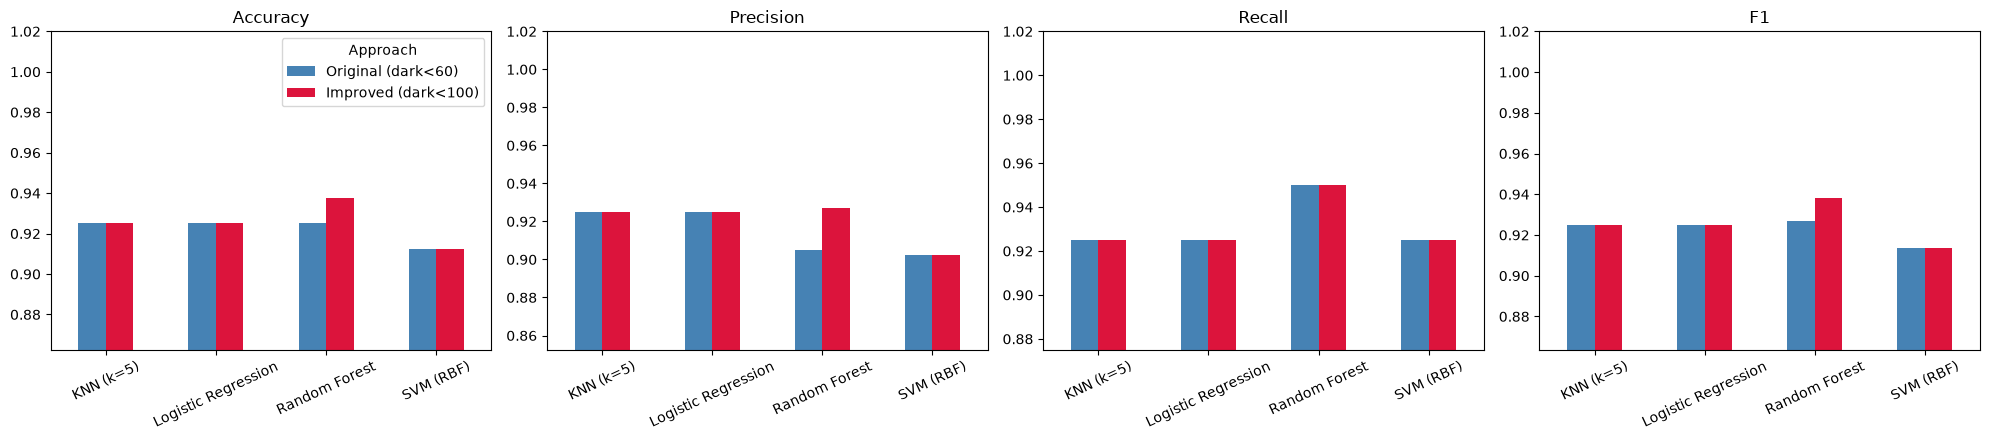

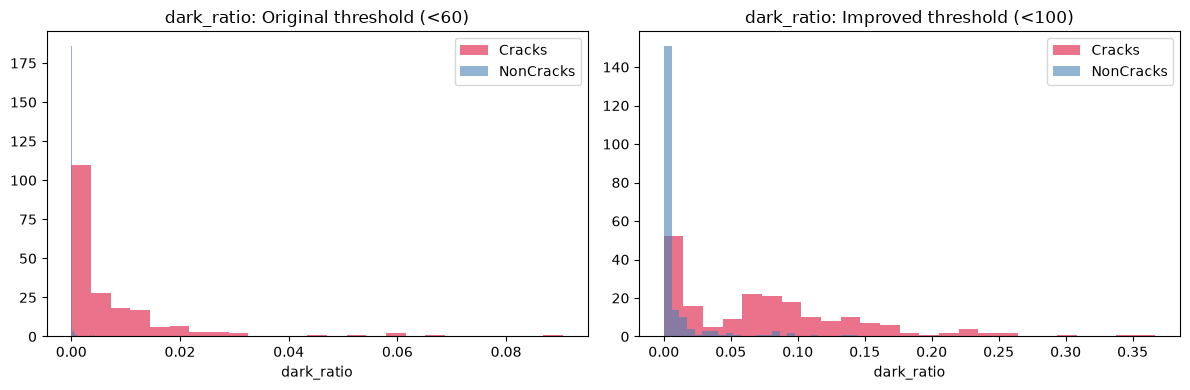

,Acc (orig),Acc (imp),Recall (orig),Recall (imp),F1 (orig),F1 (imp),Acc Δ,Recall Δ,F1 Δ,Train time Δ (s)
Model,,,,,,,,,,
Logistic Regression,0.9250,0.9250,0.925,0.925,0.9250,0.9250,0.0000,0.0,0.0000,-0.0015
SVM (RBF),0.9125,0.9125,0.925,0.925,0.9136,0.9136,0.0000,0.0,0.0000,-0.0010
Random Forest,0.9250,0.9375,0.950,0.950,0.9268,0.9383,0.0125,0.0,0.0114,0.0012
KNN (k=5),0.9250,0.9250,0.925,0.925,0.9250,0.9250,0.0000,0.0,0.0000,-0.0019


In [23]:
metrics = ["Accuracy", "Precision", "Recall", "F1"]
order = ["Original (dark<60)", "Improved (dark<100)"]

fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
for ax, m in zip(axes, metrics):
    piv = image_cmp.pivot(index="Model", columns="Approach", values=m)[order]
    piv.plot(kind="bar", ax=ax, rot=25, color=["steelblue", "crimson"], legend=(m == "Accuracy"))
    ax.set_title(m)
    ax.set_xlabel("")
    ax.set_ylim(max(0, piv.min().min() - 0.05), 1.02)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "image_before_vs_after_metrics.png"), dpi=130, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (fdf, title) in zip(axes, [(feature_df, "Original threshold (<60)"),
                                   (feature_df_imp, "Improved threshold (<100)")]):
    for folder, color in [("Cracks", "crimson"), ("NonCracks", "steelblue")]:
        ax.hist(fdf[fdf.folder == folder]["dark_ratio"], bins=25,
                alpha=0.6, label=folder, color=color)
    ax.set_title(f"dark_ratio: {title}")
    ax.set_xlabel("dark_ratio"); ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "dark_ratio_before_vs_after.png"), dpi=130, bbox_inches="tight")
plt.show()

o = res_orig.set_index("Model")
i = res_imp.set_index("Model")

delta = pd.DataFrame({
    "Acc (orig)": o["Accuracy"], "Acc (imp)": i["Accuracy"],
    "Recall (orig)": o["Recall"], "Recall (imp)": i["Recall"],
    "F1 (orig)": o["F1"], "F1 (imp)": i["F1"],
})
delta["Acc Δ"]    = delta["Acc (imp)"]    - delta["Acc (orig)"]
delta["Recall Δ"] = delta["Recall (imp)"] - delta["Recall (orig)"]
delta["F1 Δ"]     = delta["F1 (imp)"]     - delta["F1 (orig)"]
delta["Train time Δ (s)"] = i["Train (s)"] - o["Train (s)"]

delta.to_csv(os.path.join(OUTPUT_DIR, "image_delta_table.csv"))
delta.round(4)



In [24]:
expected = [
    "image_features.csv", "image_features_improved.csv",
    "canny_samples.png", "feature_distributions.png",
    "confusion_matrices.png", "feature_importance.png",
    "image_model_results.csv", "image_original_vs_improved.csv",
    "image_before_vs_after_metrics.png", "dark_ratio_before_vs_after.png",
    "image_delta_table.csv", "text_results_original.csv",
    "text_results_variants.csv", "text_confusion_matrices.png",
    "text_tradeoff.png", "final_summary.csv",
]
for f in expected:
    print("OK     " if os.path.exists(os.path.join(OUTPUT_DIR, f)) else "MISSING", f)

mb = os.path.getsize(os.path.join(DATA_DIR, "emails.csv")) / 1e6
print(f"\nemails.csv = {mb:.1f} MB ->", "ignore it in .gitignore" if mb > 50 else "safe to commit")

OK      image_features.csv
OK      image_features_improved.csv
OK      canny_samples.png
OK      feature_distributions.png
OK      confusion_matrices.png
OK      feature_importance.png
OK      image_model_results.csv
OK      image_original_vs_improved.csv
OK      image_before_vs_after_metrics.png
OK      dark_ratio_before_vs_after.png
OK      image_delta_table.csv
OK      text_results_original.csv
OK      text_results_variants.csv
OK      text_confusion_matrices.png
OK      text_tradeoff.png
OK      final_summary.csv

emails.csv = 31.2 MB -> safe to commit


In [25]:
with open("requirements.txt", "w") as f:
    f.write("numpy\npandas\nopencv-python\nmatplotlib\nscikit-learn\njupyter\n")
print(open("requirements.txt").read())

numpy
pandas
opencv-python
matplotlib
scikit-learn
jupyter

